# Credit Scoring Model

## Task 1 - CodeAlpha Machine Learning Internship

### Objective
Build a machine learning classification model to predict an individual's creditworthiness using financial and credit history data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
train = pd.read_csv("Data/train.csv", low_memory=False)
test = pd.read_csv("Data/test.csv", low_memory=False)

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

display(train.head())

Training Dataset Shape: (100000, 28)
Testing Dataset Shape: (50000, 27)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


## Step 2: Exploratory Data Analysis (EDA)

In this step, we explore the dataset structure, identify missing values, examine data types, and analyze the target variable before preprocessing.

In [3]:
# Dataset information
print("Dataset Information:")
train.info()

print("\nColumn Names:")
print(train.columns.tolist())

print("\nMissing Values:")
display(train.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Rows:", train.duplicated().sum())

print("\nTarget Distribution:")
print(train["Credit_Score"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  str    
 13  Type_of_Loan              88592 non

Monthly_Inhand_Salary       15002
Type_of_Loan                11408
Name                         9985
Credit_History_Age           9030
Num_of_Delayed_Payment       7002
Amount_invested_monthly      4479
Num_Credit_Inquiries         1965
Monthly_Balance              1200
Month                           0
Age                             0
Customer_ID                     0
ID                              0
Interest_Rate                   0
Num_Credit_Card                 0
Num_Bank_Accounts               0
Annual_Income                   0
SSN                             0
Occupation                      0
Delay_from_due_date             0
Num_of_Loan                     0
Outstanding_Debt                0
Credit_Mix                      0
Changed_Credit_Limit            0
Credit_Utilization_Ratio        0
Total_EMI_per_month             0
Payment_of_Min_Amount           0
Payment_Behaviour               0
Credit_Score                    0
dtype: int64


Duplicate Rows: 0

Target Distribution:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


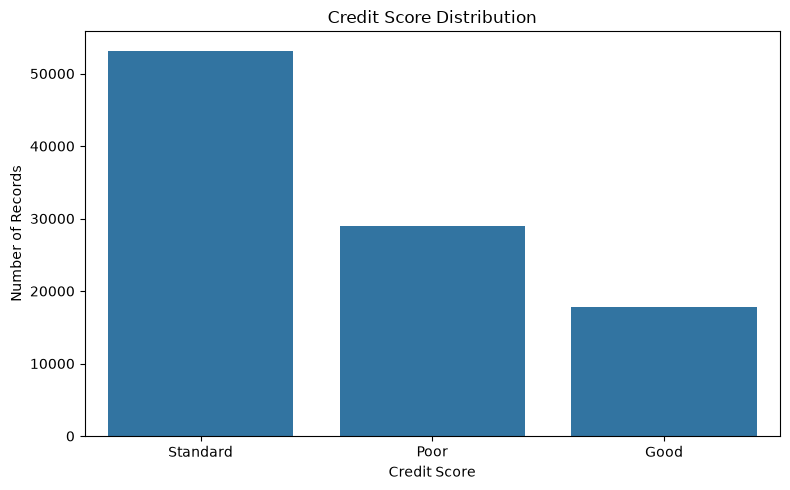

In [4]:
# Target distribution visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="Credit_Score",
    order=train["Credit_Score"].value_counts().index
)

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## Step 3: Data Cleaning and Preprocessing

In this step, we clean invalid numerical values, convert incorrectly formatted columns into numeric data types, and prepare the dataset for machine learning.

Missing values and categorical features will be handled in the following steps.

In [5]:
# Create a copy to preserve the original dataset
df = train.copy()

# Convert numeric columns stored as strings
numeric_columns = [
    "Age",
    "Annual_Income",
    "Num_of_Loan",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Outstanding_Debt",
    "Amount_invested_monthly",
    "Monthly_Balance"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace("_", "", regex=False),
        errors="coerce"
    )

# Replace invalid values with NaN
df.loc[~df["Age"].between(18, 100), "Age"] = np.nan

df.loc[
    ~df["Annual_Income"].between(0, 1_000_000),
    "Annual_Income"
] = np.nan

df.loc[
    ~df["Num_of_Loan"].between(0, 100),
    "Num_of_Loan"
] = np.nan

df.loc[
    ~df["Num_of_Delayed_Payment"].between(0, 100),
    "Num_of_Delayed_Payment"
] = np.nan

# Check cleaning results
print("Dataset Shape:", df.shape)

print("\nNumeric Columns Data Types:")
print(df[numeric_columns].dtypes)

print("\nMissing Values After Cleaning:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(15)
)

Dataset Shape: (100000, 28)

Numeric Columns Data Types:
Age                        float64
Annual_Income              float64
Num_of_Loan                float64
Num_of_Delayed_Payment     float64
Changed_Credit_Limit       float64
Outstanding_Debt           float64
Amount_invested_monthly    float64
Monthly_Balance            float64
dtype: object

Missing Values After Cleaning:


Monthly_Inhand_Salary      15002
Type_of_Loan               11408
Name                        9985
Credit_History_Age          9030
Age                         8482
Num_of_Delayed_Payment      8370
Amount_invested_monthly     4479
Num_of_Loan                 4313
Changed_Credit_Limit        2091
Num_Credit_Inquiries        1965
Monthly_Balance             1200
Annual_Income                961
Interest_Rate                  0
Num_Credit_Card                0
Num_Bank_Accounts              0
dtype: int64

## Step 4: Feature Preparation

In this step, irrelevant identifiers and personal information are removed, additional financial features are created, and categorical variables are prepared for machine learning.

Missing value imputation and categorical encoding will be performed after splitting the data to prevent data leakage.

In [6]:
# Create a working copy
model_df = df.copy()

# Remove identifiers and personal information
columns_to_drop = [
    "ID",
    "Customer_ID",
    "Name",
    "SSN",
    "Month",
    "Type_of_Loan"
]

model_df = model_df.drop(columns=columns_to_drop)

# Clean categorical placeholders
categorical_columns = [
    "Occupation",
    "Credit_Mix",
    "Payment_of_Min_Amount",
    "Payment_Behaviour"
]

for col in categorical_columns:
    model_df[col] = model_df[col].replace(
        ["_______", "______", "____", "_", ""],
        np.nan
    )

# Feature Engineering
model_df["Debt_to_Income_Ratio"] = (
    model_df["Outstanding_Debt"] /
    model_df["Annual_Income"].replace(0, np.nan)
)

model_df["Loan_to_Income_Ratio"] = (
    model_df["Total_EMI_per_month"] * 12 /
    model_df["Annual_Income"].replace(0, np.nan)
)

# Check results
print("Dataset Shape:", model_df.shape)

print("\nCategorical Columns:")
print(model_df.select_dtypes(include="object").columns.tolist())

print("\nMissing Values:")
display(
    model_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

display(model_df.head())

Dataset Shape: (100000, 24)

Categorical Columns:
['Occupation', 'Credit_Mix', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']

Missing Values:


Credit_Mix                 20195
Monthly_Inhand_Salary      15002
Credit_History_Age          9030
Age                         8482
Num_of_Delayed_Payment      8370
Occupation                  7062
Amount_invested_monthly     4479
Num_of_Loan                 4313
Changed_Credit_Limit        2091
Num_Credit_Inquiries        1965
Monthly_Balance             1200
Annual_Income                961
Loan_to_Income_Ratio         961
Debt_to_Income_Ratio         961
Num_Bank_Accounts              0
dtype: int64

,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,...,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Debt_to_Income_Ratio,Loan_to_Income_Ratio
0,23.0,Scientist,19114.12,1824.843333,3,4,3,4.0,3,7.0,...,26.822620,22 Years and 1 Months,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good,0.042376,0.031124
1,23.0,Scientist,19114.12,NaN,3,4,3,4.0,-1,NaN,...,31.944960,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good,0.042376,0.031124
2,NaN,Scientist,19114.12,NaN,3,4,3,4.0,3,7.0,...,28.609352,22 Years and 3 Months,No,49.574949,81.699521,Low_spent_Medium_value_payments,331.209863,Good,0.042376,0.031124
3,23.0,Scientist,19114.12,NaN,3,4,3,4.0,5,4.0,...,31.377862,22 Years and 4 Months,No,49.574949,199.458074,Low_spent_Small_value_payments,223.451310,Good,0.042376,0.031124
4,23.0,Scientist,19114.12,1824.843333,3,4,3,4.0,6,NaN,...,24.797347,22 Years and 5 Months,No,49.574949,41.420153,High_spent_Medium_value_payments,341.489231,Good,0.042376,0.031124


## Step 5: Train-Test Split

The dataset is split into training and testing sets using customer-based grouping to prevent data leakage.

An 80/20 split is used, ensuring that records belonging to the same customer are not shared between the training and testing sets.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

# Separate features and target
X = model_df.drop(columns=["Credit_Score"])
y = model_df["Credit_Score"]

# Use customer IDs to prevent data leakage
groups = df["Customer_ID"]

# Customer-based train-test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify that customers do not overlap
train_customers = set(groups.iloc[train_idx])
test_customers = set(groups.iloc[test_idx])

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

print("\nOverlapping Customers:",
      len(train_customers.intersection(test_customers)))

Training Shape: (80000, 23)
Testing Shape: (20000, 23)

Training Target Distribution:
Credit_Score
Standard    0.532425
Poor        0.290900
Good        0.176675
Name: proportion, dtype: float64

Testing Target Distribution:
Credit_Score
Standard    0.5290
Poor        0.2863
Good        0.1847
Name: proportion, dtype: float64

Overlapping Customers: 0


## Step 6: Data Preprocessing Pipeline

A preprocessing pipeline is created to handle missing values, encode categorical variables, and scale numerical features.

The pipeline is fitted only on the training dataset to prevent data leakage.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Convert credit history duration into months
def credit_history_to_months(value):
    if pd.isna(value):
        return np.nan

    import re

    years = re.search(r"(\d+)\s*Years?", str(value))
    months = re.search(r"(\d+)\s*Months?", str(value))

    if not years and not months:
        return np.nan

    return (
        (int(years.group(1)) * 12 if years else 0)
        + (int(months.group(1)) if months else 0)
    )

for dataset in [X_train, X_test]:
    dataset["Credit_History_Months"] = (
        dataset["Credit_History_Age"]
        .apply(credit_history_to_months)
    )

    dataset.drop(columns=["Credit_History_Age"], inplace=True)

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nTraining Processed Shape:", X_train_processed.shape)
print("Testing Processed Shape:", X_test_processed.shape)

print("\nMissing Values in Training:",
      np.isnan(X_train_processed).sum())

print("Missing Values in Testing:",
      np.isnan(X_test_processed).sum())

Numerical Features: 19
Categorical Features: 4

Training Processed Shape: (80000, 47)
Testing Processed Shape: (20000, 47)

Missing Values in Training: 0
Missing Values in Testing: 0


## Step 7: Model Training and Evaluation

Three classification algorithms are trained and evaluated:

- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

Performance is measured using Accuracy, Precision, Recall, F1-Score, and multi-class ROC-AUC.

Weighted averages are used to account for class imbalance.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

# Store results and trained models
results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_proba,
        labels=model.classes_,
        multi_class="ovr",
        average="weighted"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = model

    print(f"{name} completed!")

# Compare model performance
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
)

display(results_df.round(4))


Training Logistic Regression...
Logistic Regression completed!

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.6909,0.7152,0.6909,0.6937,0.8284
1,Decision Tree,0.6518,0.6770,0.6518,0.6549,0.7582
0,Logistic Regression,0.6296,0.6622,0.6296,0.6318,0.7558


## Step 8: Model Performance Analysis

The best-performing model, Random Forest, is evaluated using a confusion matrix and a detailed classification report.

This analysis helps identify classification errors and assess precision, recall, and F1-score for each credit score category.

Random Forest Classification Report:

              precision    recall  f1-score   support

        Good     0.5442    0.7669    0.6366      3694
        Poor     0.6660    0.7482    0.7047      5726
    Standard     0.8015    0.6335    0.7076     10580

    accuracy                         0.6909     20000
   macro avg     0.6706    0.7162    0.6830     20000
weighted avg     0.7152    0.6909    0.6937     20000



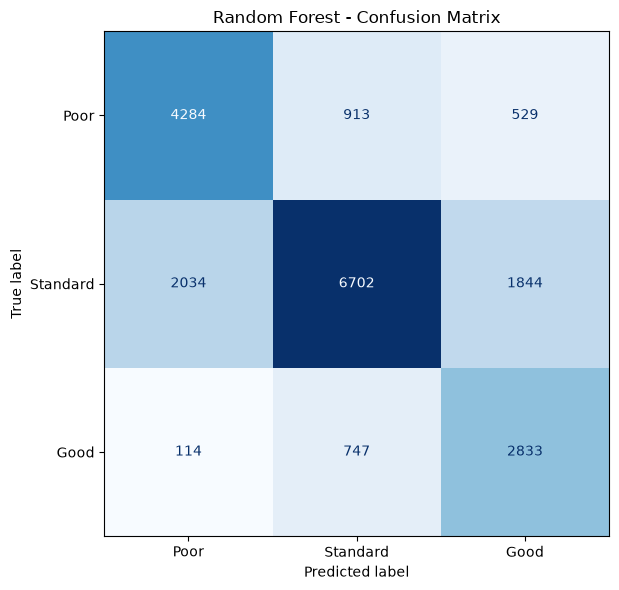

In [10]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Select the best model
best_model = trained_models["Random Forest"]

# Generate predictions
y_pred_best = best_model.predict(X_test_processed)

# Classification Report
print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_best,
        digits=4
    )
)

# Confusion Matrix
labels = ["Poor", "Standard", "Good"]

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 9: Random Forest Hyperparameter Optimization

RandomizedSearchCV is used to optimize the Random Forest classifier.

GroupKFold cross-validation is applied to prevent customer-level data leakage.

The optimization objective is the weighted F1-score, while the recall of the Poor credit category is also monitored.

In [11]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Customer groups for training data
train_groups = df.loc[X_train.index, "Customer_ID"]

# Build pipeline
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [15, 20, 25, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

# Group-based cross-validation
group_cv = GroupKFold(n_splits=3)

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=12,
    scoring="f1_weighted",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using raw training features
random_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}

Best Cross-Validation F1-Score:
0.6947


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Best tuned pipeline
tuned_rf = random_search.best_estimator_

# Predict using raw test features
y_pred_tuned = tuned_rf.predict(X_test)
y_proba_tuned = tuned_rf.predict_proba(X_test)

# Evaluate
tuned_results = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(
        y_test, y_pred_tuned, average="weighted"
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned, average="weighted"
    ),
    "F1-Score": f1_score(
        y_test, y_pred_tuned, average="weighted"
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        y_proba_tuned,
        labels=tuned_rf.classes_,
        multi_class="ovr",
        average="weighted"
    )
}

comparison_df = pd.concat([
    results_df[results_df["Model"] == "Random Forest"],
    pd.DataFrame([tuned_results])
], ignore_index=True)

display(comparison_df.round(4))

print("\nTuned Random Forest Classification Report:")
print(classification_report(y_test, y_pred_tuned, digits=4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.6909,0.7152,0.6909,0.6937,0.8284
1,Tuned Random Forest,0.6979,0.7105,0.6979,0.7006,0.8303



Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

        Good     0.5580    0.7185    0.6282      3694
        Poor     0.6887    0.7174    0.7028      5726
    Standard     0.7755    0.6802    0.7247     10580

    accuracy                         0.6979     20000
   macro avg     0.6741    0.7053    0.6852     20000
weighted avg     0.7105    0.6979    0.7006     20000



## Step 10: ROC Curve Analysis

The optimized Random Forest classifier is evaluated using One-vs-Rest ROC curves.

ROC-AUC measures the model's ability to distinguish each credit score category from the other categories.

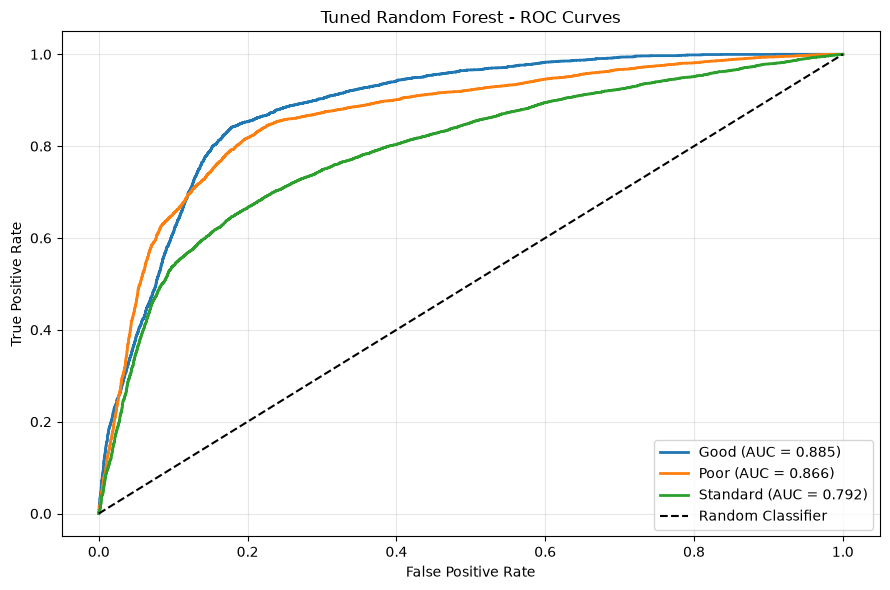

In [13]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Final model
final_model = tuned_rf

# Predict probabilities
y_proba_final = final_model.predict_proba(X_test)

# Class labels
classes = final_model.classes_

# Binarize actual labels
y_test_bin = label_binarize(
    y_test,
    classes=classes
)

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_proba_final[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned Random Forest - ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 11: Feature Importance Analysis

Feature importance is extracted from the optimized Random Forest classifier to identify the most influential variables in credit score prediction.

The top 15 features are visualized to better understand the model's decision-making process.

,Feature,Importance
11,num__Outstanding_Debt,0.109013
5,num__Interest_Rate,0.077490
7,num__Delay_from_due_date,0.066593
18,num__Credit_History_Months,0.053383
16,num__Debt_to_Income_Ratio,0.051306
35,cat__Credit_Mix_Good,0.046010
9,num__Changed_Credit_Limit,0.043716
17,num__Loan_to_Income_Ratio,0.039953
10,num__Num_Credit_Inquiries,0.039061
1,num__Annual_Income,0.037781


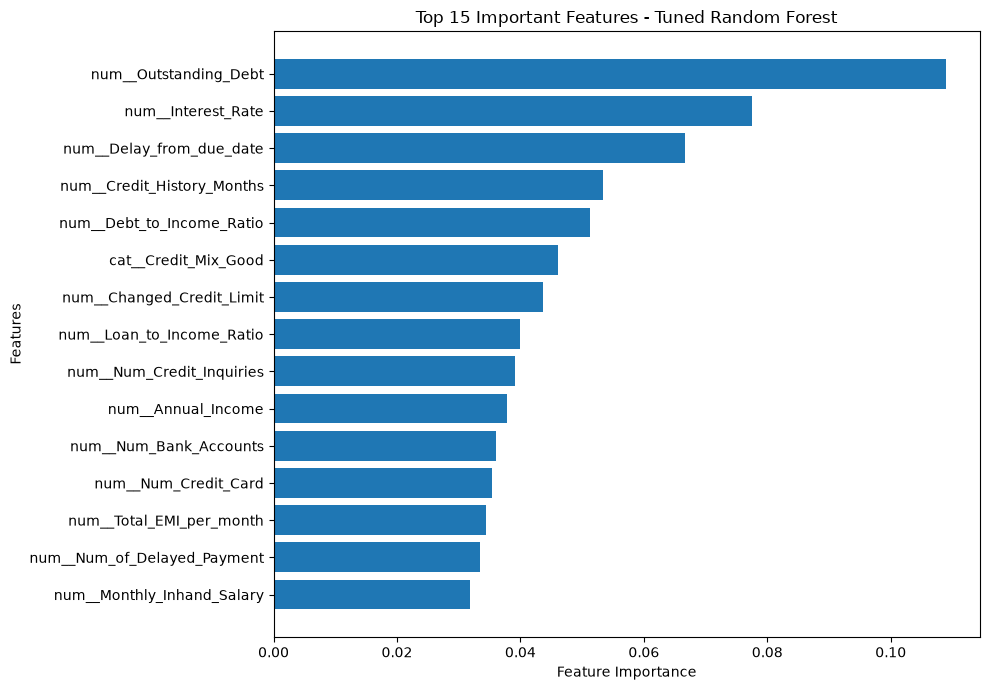

In [14]:
# Extract preprocessing and classifier
final_preprocessor = final_model.named_steps["preprocessing"]
final_classifier = final_model.named_steps["classifier"]

# Get transformed feature names
feature_names = final_preprocessor.get_feature_names_out()

# Get feature importance values
importances = final_classifier.feature_importances_

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(feature_importance_df.head(15))

# Plot top 15 features
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Tuned Random Forest")

plt.tight_layout()
plt.show()

## Step 12: Data Leakage and Final Validation

The final model is checked for potentially sensitive identifiers, target leakage, and consistency between training and testing features.

The objective is to ensure that the credit scoring model uses relevant financial information rather than customer identifiers or the target variable itself.

In [15]:
# Check for unwanted features
excluded_columns = [
    "ID",
    "Customer_ID",
    "Name",
    "SSN",
    "Credit_Score"
]

print("Feature Leakage Check:")
print("-" * 40)

for col in excluded_columns:
    print(f"{col}: {'FOUND' if col in X_train.columns else 'Not included'}")

print("\nTraining Features:", X_train.shape[1])
print("Testing Features:", X_test.shape[1])

print("\nTrain/Test Feature Match:")
print(X_train.columns.equals(X_test.columns))

print("\nFinal Model:")
print(final_model.named_steps["classifier"])

print("\nFinal Model Performance:")
display(comparison_df.round(4))

Feature Leakage Check:
----------------------------------------
ID: Not included
Customer_ID: Not included
Name: Not included
SSN: Not included
Credit_Score: Not included

Training Features: 23
Testing Features: 23

Train/Test Feature Match:
True

Final Model:
RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       min_samples_split=5, n_estimators=200, n_jobs=1,
                       random_state=42)

Final Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.6909,0.7152,0.6909,0.6937,0.8284
1,Tuned Random Forest,0.6979,0.7105,0.6979,0.7006,0.8303


## Step 13: Save the Final Model

The optimized Random Forest pipeline is saved using Joblib.

The saved pipeline includes both data preprocessing and the trained classifier, allowing consistent predictions on new customer records.

In [16]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save final pipeline
model_path = "models/credit_scoring_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)

Model saved successfully!
Path: models/credit_scoring_model.pkl


In [17]:
# Load saved model
loaded_model = joblib.load(
    "models/credit_scoring_model.pkl"
)

# Test predictions
sample_data = X_test.head(5)

predictions = loaded_model.predict(sample_data)

print("Predictions:", predictions)
print("Actual Labels:", y_test.head(5).values)

# Verify saved model
original_predictions = final_model.predict(sample_data)

print(
    "Saved Model Verification:",
    (predictions == original_predictions).all()
)

Predictions: ['Standard' 'Standard' 'Standard' 'Standard' 'Standard']
Actual Labels: <StringArray>
['Standard', 'Standard', 'Standard', 'Standard', 'Standard']
Length: 5, dtype: str
Saved Model Verification: True


## Step 14: Final Conclusion

This project developed a machine learning-based Credit Scoring Model to classify customers into three credit score categories: **Poor, Standard, and Good**.

### Project Workflow

1. Loaded and explored 100,000 customer credit records.
2. Cleaned invalid values and handled missing data.
3. Applied feature engineering to create financial indicators.
4. Split the dataset into training and testing sets with no overlapping customers.
5. Applied numerical and categorical preprocessing.
6. Trained Logistic Regression, Decision Tree, and Random Forest classifiers.
7. Optimized Random Forest using RandomizedSearchCV and group-based cross-validation.
8. Evaluated model performance using classification metrics, confusion matrices, and ROC curves.
9. Analyzed the most important financial features.
10. Saved and verified the final trained pipeline using Joblib.

### Final Model Performance

| Metric             | Result              |
| ------------------ | ------------------- |
| Model              | Tuned Random Forest |
| Accuracy           | 69.79%              |
| Weighted Precision | 71.05%              |
| Weighted Recall    | 69.79%              |
| Weighted F1-Score  | 70.06%              |
| ROC-AUC            | 83.03%              |

### Key Findings

Outstanding Debt, Interest Rate, Delay from Due Date, Credit History, and Debt-to-Income Ratio were among the most influential features.

Hyperparameter tuning improved the overall weighted F1-score, although recall for the Poor credit category decreased compared with the original Random Forest.

### Conclusion

The project demonstrates an end-to-end machine learning workflow for credit score classification, including data preprocessing, feature engineering, model training, optimization, evaluation, and model persistence.

The optimized Random Forest achieved the strongest overall weighted F1-score among the evaluated configurations. Further validation and improvements would be necessary before any real-world financial decision-making application.
